Firstable, We have to read the json. This json has the following structure:

{
  "xsec": 0.281,

  "year": "2022",

  "treeName": "Events",

  "histAxisName": "ttll_private2022",

  "options": "",

  "WCnames": [
    "cQu8",
    "ctu8",
    "cQu1",
    "ctd8",
    "cQlMi",
    "cpQ3",
    "ctlTi",
    "ctG",
    "ctZ",
    "ctW",
    "ctli",
    "ctb8",
    "cbW",
    "cQl3i",
    "cQq13",
    "cptb",
    "ctp",
    "ctei",
    "cpQM",
    "ctlSi",
    "cQq83",
    "cQq81",
    "ctq1",
    "ctu1",
    "cQei",
    "cQb8",
    "cpt",
    "ctq8",
    "cQd1",
    "cQq11",
    "cQd8",
    "ctd1"
  ],

  "files": [
    "/store/user/ywan2/FullProduction/Run3/2022/Round1/Batch1/NAOD_step/v1/lobster_20251202_1202/nAOD_step_ttllNuNuJetNoHiggs_Run3Dim6TopWithTOP22006_run0/NAOD-00000_24270.root",
    "/store/user/ywan2/FullProduction/Run3/2022/Round1/Batch1/NAOD_step/v1/lobster_20251202_1202/nAOD_step_ttllNuNuJetNoHiggs_Run3Dim6TopWithTOP22006_run0/NAOD-00000_9375.root",

  ],

  "nEvents": 2260431,

  "nGenEvents": 2260431,

  "nSumOfWeights": 3134.82568011874,

  "isData": false,

  "path": "/cms/cephfs/data/store/user/ywan2/FullProduction/Run3/2022/Round1/Batch1/NAOD_step/v1/lobster_20251202_1202/nAOD_step_ttllNuNuJetNoHiggs_Run3Dim6TopWithTOP22006_run0/",

  "nSumOfWeights_ISRUp": 3243.112032955547,
  "nSumOfWeights_ISRDown": 3005.3432288592376,
  "nSumOfWeights_FSRUp": 3137.721731798729,
  "nSumOfWeights_FSRDown": 3130.492076250258,
  "nSumOfWeights_renormUp": 2644.708885361861,
  "nSumOfWeights_renormDown": 3783.662633111153,
  "nSumOfWeights_factUp": 2898.841866392305,
  "nSumOfWeights_factDown": 3412.586251676314,
  "nSumOfWeights_renormDown_factUp": 3496.956890186705,
  "nSumOfWeights_renormUp_factDown": 2877.421669179921
}

In [2]:
import sys
import hist
import boost_histogram as bh
import coffea
import awkward as ak
import correctionlib
import topcoffea
import topeft

print("Python          :", sys.version)
print("numpy           :", __import__("numpy").__version__)
print("awkward         :", ak.__version__)
print("coffea          :", coffea.__version__)
print("hist            :", hist.__version__)
print("boost-histogram :", bh.__version__)
print("correctionlib   :", correctionlib.__version__)
print("topcoffea       :", topcoffea.__file__)
print("topeft          :", topeft.__file__)

print("\nMultiCell support")
print("hist.storage.MultiCell :", hasattr(hist.storage, "MultiCell"))
print("bh.storage.MultiCell   :", hasattr(bh.storage, "MultiCell"))


Python          : 3.9.23 | packaged by conda-forge | (main, Jun  4 2025, 17:57:12) 
[GCC 13.3.0]
numpy           : 1.23.5
awkward         : 1.10.5
coffea          : 0.7.21
hist            : 2.9.2
boost-histogram : 1.6.1
correctionlib   : 2.7.0
topcoffea       : /users/ldiazlie/topeft/external/topcoffea/topcoffea/__init__.py
topeft          : /users/ldiazlie/topeft/topeft/__init__.py

MultiCell support
hist.storage.MultiCell : False
bh.storage.MultiCell   : False


In [1]:
import json

with open("ttll_2022.json", "r") as f:
    sample = json.load(f)

print(sample.keys())

dict_keys(['xsec', 'year', 'treeName', 'histAxisName', 'options', 'WCnames', 'files', 'nEvents', 'nGenEvents', 'nSumOfWeights', 'isData', 'path', 'nSumOfWeights_ISRUp', 'nSumOfWeights_ISRDown', 'nSumOfWeights_FSRUp', 'nSumOfWeights_FSRDown', 'nSumOfWeights_renormUp', 'nSumOfWeights_renormDown', 'nSumOfWeights_factUp', 'nSumOfWeights_factDown', 'nSumOfWeights_renormDown_factUp', 'nSumOfWeights_renormUp_factDown'])


LEt's print the Wilson Coefficient names, which are the WCs that are related with those interactions.

In [2]:
wcs = sample["WCnames"]
print(len(wcs), wcs[:10])

32 ['cQu8', 'ctu8', 'cQu1', 'ctd8', 'cQlMi', 'cpQ3', 'ctlTi', 'ctG', 'ctZ', 'ctW']


In [3]:
files = sample["files"]
print(len(files))
print(files[0])

74
/store/user/ywan2/FullProduction/Run3/2022/Round1/Batch1/NAOD_step/v1/lobster_20251202_1202/nAOD_step_ttllNuNuJetNoHiggs_Run3Dim6TopWithTOP22006_run0/NAOD-00000_24270.root


In [8]:
n_events = sample["nEvents"]
sum_w = sample["nSumOfWeights"]

print(n_events, sum_w)

2260431 3134.82568011874


In [9]:
samples = {
    sample["histAxisName"]: {
        "files": sample["files"],
        "metadata": {
            "xsec": sample["xsec"],
            "sumw": sample["nSumOfWeights"],
            "year": sample["year"],
            "isData": sample["isData"],
        },
        "WCnames": sample["WCnames"]
    }
}

Opening one of the directory files:

In [11]:
print(sample["files"][0])

/store/user/ywan2/FullProduction/Run3/2022/Round1/Batch1/NAOD_step/v1/lobster_20251202_1202/nAOD_step_ttllNuNuJetNoHiggs_Run3Dim6TopWithTOP22006_run0/NAOD-00000_24270.root


Let's load the first file, which is a root file. The data is hosted in the ND CEph. We can call them remotely using XROOTD. Actually, this is the standard way to call different dataset events in the LHC. 

In [14]:
import uproot

fname = (
    "root://cmsxrootd.crc.nd.edu/"
    + sample["files"][0]
)

file = uproot.open(fname)

print(file.keys())

['untagged;1', 'Events;1', 'LuminosityBlocks;1', 'Runs;1', 'MetaData;1', 'ParameterSets;1']


260608 16:02:10 84840 crypto_Factory::GetCryptoFactory: Plugin version cryptoloader v5.8.4 is incompatible with cryptossl v5.9.2 (must be <= 5.8.x) in cryptolib libXrdCryptossl-5.so
260608 16:02:10 84840 crypto_Factory::GetCryptoFactory: problems finding crypto factory object creator XrdCryptosslFactoryObject


Let's print all the different branches that this file contains. It has 1844 types of variables and we print the first 10 ones.

In [15]:
tree = file["Events"]
print(len(tree.keys()))
print(tree.keys()[:10])

1844
['run', 'luminosityBlock', 'event', 'bunchCrossing', 'HTXS_njets25', 'HTXS_njets30', 'HTXS_stage1_1_cat_pTjet25GeV', 'HTXS_stage1_1_cat_pTjet30GeV', 'HTXS_stage1_1_fine_cat_pTjet25GeV', 'HTXS_stage1_1_fine_cat_pTjet30GeV']


It's saying give me an Awkward array of the branch "event" of the TTree.

In [16]:
events = tree.arrays(
    ["event"],
    entry_stop=10,
    library="ak"
)

print(events)

[{event: 17}, {event: 7}, {event: 22}, ... {event: 13}, {event: 38}, {event: 2}]


### Basic distributions 


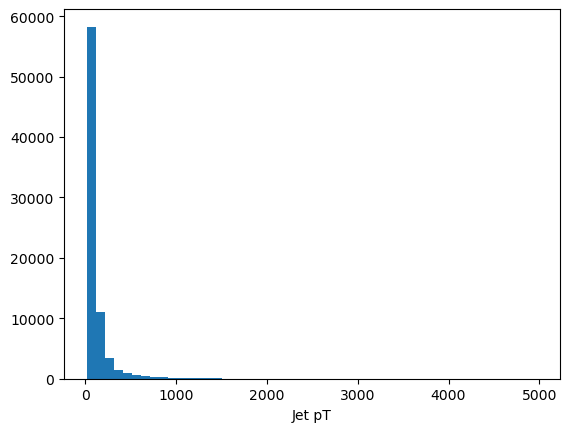

In [17]:
jets = tree.arrays(["Jet_pt"], library="ak", entry_stop=10000)

import awkward as ak

all_jet_pt = ak.flatten(jets["Jet_pt"])

import matplotlib.pyplot as plt

plt.hist(all_jet_pt, bins=50)
plt.xlabel("Jet pT")
plt.show()


### Jet multiplicity

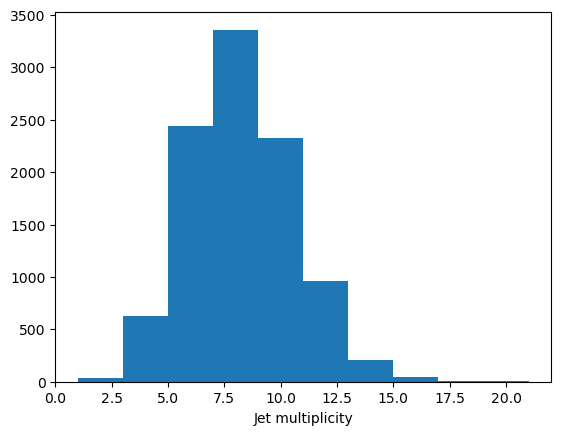

In [18]:
njet = tree.arrays(["nJet"], library="ak", entry_stop=10000)

plt.hist(njet["nJet"], bins=10)
plt.xlabel("Jet multiplicity")
plt.show()

### Scattering between two correlated variables

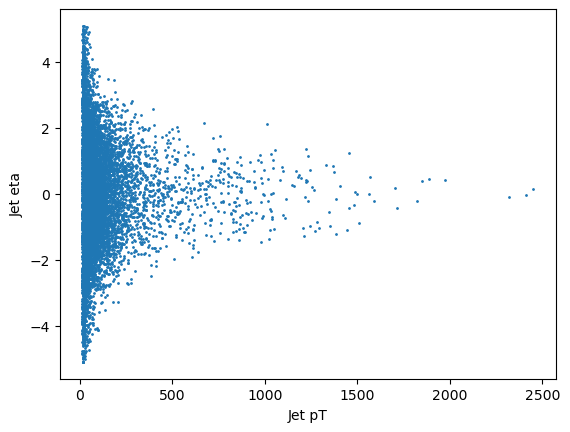

In [19]:
arr = tree.arrays(["Jet_pt", "Jet_eta"], library="ak", entry_stop=5000)

pt = ak.flatten(arr["Jet_pt"])
eta = ak.flatten(arr["Jet_eta"])

plt.scatter(pt[:10000], eta[:10000], s=1)
plt.xlabel("Jet pT")
plt.ylabel("Jet eta")
plt.show()

In TopCoffea terms this is a:

“sample card” for EFT-aware MC production

(array([    0.,     0.,     0.,     0.,     0.,     0.,     0.,     0.,
            0.,     0.,     0.,     0.,     0.,     0.,     0.,     0.,
            0.,     0.,     0.,     0.,     0.,     0.,     0.,     0.,
            0., 28647.,     0.,     0.,     0.,     0.,     0.,     0.,
            0.,     0.,     0.,     0.,     0.,     0.,     0.,     0.,
            0.,     0.,     0.,     0.,     0.,     0.,     0.,     0.,
            0.,     0.]),
 array([0.5       , 0.51999998, 0.54000002, 0.56      , 0.57999998,
        0.60000002, 0.62      , 0.63999999, 0.66000003, 0.68000001,
        0.69999999, 0.72000003, 0.74000001, 0.75999999, 0.77999997,
        0.80000001, 0.81999999, 0.83999997, 0.86000001, 0.88      ,
        0.89999998, 0.92000002, 0.94      , 0.95999998, 0.98000002,
        1.        , 1.01999998, 1.03999996, 1.05999994, 1.08000004,
        1.10000002, 1.12      , 1.13999999, 1.15999997, 1.17999995,
        1.20000005, 1.22000003, 1.24000001, 1.25999999, 1.27999997

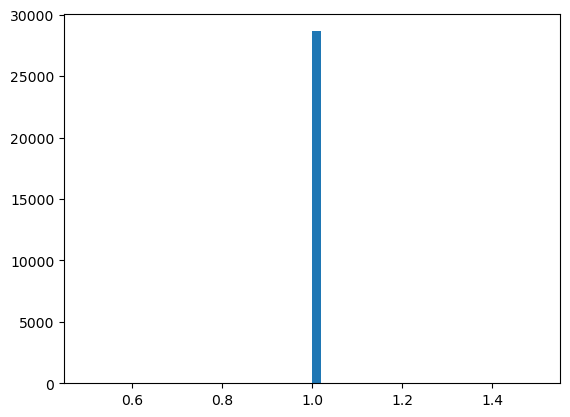

In [20]:
w = tree.arrays(["genWeight"], library="ak")
plt.hist(w["genWeight"], bins=50)

## Top-coffea

In [21]:
from coffea.nanoevents import NanoEventsFactory

fname = "root://cmsxrootd.crc.nd.edu/" + sample["files"][0]

events = NanoEventsFactory.from_root(
    fname,
    treepath="Events"
).events()

In [22]:
events.fields

['TrigObj',
 'HLTriggerFirstPath',
 'LHEPart',
 'GenMET',
 'genWeight',
 'Jet',
 'Pileup',
 'HLT',
 'GenProton',
 'HTXS',
 'Generator',
 'OtherPV',
 'FatJet',
 'DeepMETResolutionTune',
 'luminosityBlock',
 'GenIsolatedPhoton',
 'SoftActivityJetHT5',
 'GenDressedLepton',
 'SoftActivityJetNjets2',
 'SoftActivityJetHT10',
 'RawPuppiMET',
 'Tau',
 'PSWeight',
 'SoftActivityJetNjets5',
 'boostedTau',
 'SV',
 'GenJetAK8',
 'GenPart',
 'SoftActivityJetNjets10',
 'WCnames',
 'Rho',
 'Photon',
 'event',
 'DeepMETResponseTune',
 'run',
 'L1Reco',
 'Flag',
 'BeamSpot',
 'SubGenJetAK8',
 'LHEScaleWeight',
 'SoftActivityJetHT2',
 'SoftActivityJet',
 'Muon',
 'TkMET',
 'RawMET',
 'genTtbarId',
 'PV',
 'LowPtElectron',
 'Electron',
 'SubJet',
 'PuppiMET',
 'CaloMET',
 'FsrPhoton',
 'LHEReweightingWeight',
 'L1',
 'CorrT1METJet',
 'MET',
 'LHEPdfWeight',
 'GenVisTau',
 'SoftActivityJetHT',
 'LHE',
 'EFTfitCoefficients',
 'GenJet',
 'HLTriggerFinalPath',
 'ChsMET',
 'bunchCrossing',
 'L1simulation',
 '

In [24]:
import hist

h = hist.Hist(
    hist.axis.Regular(50, 0, 500, name="jet_pt"),
    storage="weight"
)

In [25]:
jets = events.Jet

h.fill(
    ak.flatten(jets.pt),
    weight=ak.to_numpy(ak.flatten(events.genWeight * ak.ones_like(jets.pt)))
)

Hist(Regular(50, 0, 500, name='jet_pt'), storage=Weight()) # Sum: WeightedSum(value=215029, variance=215029) (WeightedSum(value=221893, variance=221893) with flow)

/users/ldiazlie/.conda/envs/coffea-env/lib/python3.9/site-packages/mplhep/_utils.py:1111: UserWarning: Integer weights indicate poissonian data. Will calculate Garwood interval if ``scipy`` is installed. Otherwise errors will be set to ``sqrt(w2)``.
  self.errors()


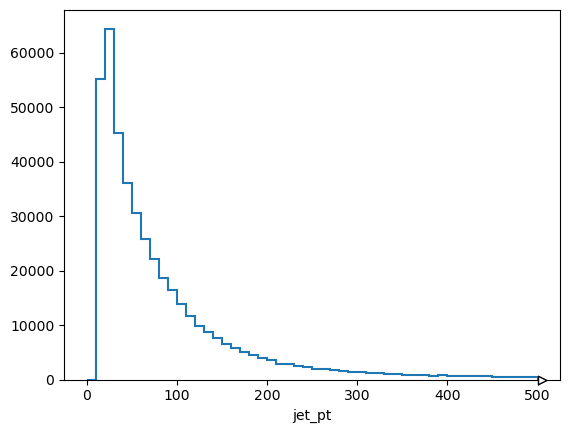

In [26]:
jet_pt = ak.flatten(events.Jet.pt)

event_weight = events.genWeight
event_weight = ak.to_numpy(ak.flatten(ak.broadcast_arrays(event_weight, events.Jet.pt)[0]))
h.fill(
    jet_pt,
    weight=event_weight
)
h.plot()
plt.show()